# Multiple Linear Regression

## 1) Import Library and Datasets

In [90]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [115]:
# Upload the csv file
from google.colab import files

files.upload()

Saving ihsg_daily.csv to ihsg_daily.csv


{'ihsg_daily.csv': b'\xef\xbb\xbf"Tanggal","Terakhir","Pembukaan","Tertinggi","Terendah","Vol.","Perubahan%"\n"25/09/2026","6.241,89","6.315,53","6.328,41","6.231,83","23,85B","-0,90%"\n"24/09/2026","6.298,61","6.364,98","6.368,57","6.287,46","23,04B","-1,20%"\n"23/09/2026","6.374,91","6.297,96","6.380,17","6.253,74","27,38B","1,56%"\n"22/09/2026","6.277,04","6.392,33","6.423,84","6.258,44","29,26B","-1,69%"\n"21/09/2026","6.384,73","6.446,90","6.451,33","6.381,57","23,21B","-0,88%"\n"18/09/2026","6.441,16","6.512,57","6.521,02","6.419,50","28,30B","-0,33%"\n"17/09/2026","6.462,43","6.455,03","6.500,41","6.418,13","24,65B","0,40%"\n"16/09/2026","6.436,85","6.453,91","6.535,46","6.436,85","22,26B","-0,38%"\n"15/09/2026","6.461,15","6.544,77","6.549,60","6.461,01","23,67B","-1,13%"\n"14/09/2026","6.534,69","6.533,87","6.550,00","6.371,40","30,63B","-0,10%"\n"11/09/2026","6.541,38","6.552,79","6.552,79","6.462,96","26,68B","-0,73%"\n"10/09/2026","6.589,34","6.688,17","6.712,50","6.585,56"

In [116]:
# Read the csv file

ihsg_daily_df = pd.read_csv('ihsg_daily.csv')

In [117]:
# Display dataset

ihsg_daily_df

,Tanggal,Terakhir,Pembukaan,Tertinggi,Terendah,Vol.,Perubahan%
0,25/09/2026,"6.241,89","6.315,53","6.328,41","6.231,83","23,85B","-0,90%"
1,24/09/2026,"6.298,61","6.364,98","6.368,57","6.287,46","23,04B","-1,20%"
2,23/09/2026,"6.374,91","6.297,96","6.380,17","6.253,74","27,38B","1,56%"
3,22/09/2026,"6.277,04","6.392,33","6.423,84","6.258,44","29,26B","-1,69%"
4,21/09/2026,"6.384,73","6.446,90","6.451,33","6.381,57","23,21B","-0,88%"
...,...,...,...,...,...,...,...
4068,08/01/2010,"2.614,37","2.586,79","2.614,54","2.583,85","7,37B","1,06%"
4069,07/01/2010,"2.586,89","2.603,50","2.611,60","2.570,27","4,55B","-0,63%"
4070,06/01/2010,"2.603,30","2.605,48","2.622,12","2.587,71","5,16B","-0,08%"
4071,05/01/2010,"2.605,28","2.575,62","2.606,07","2.575,62","5,70B","1,16%"


In [118]:
ihsg_daily_df.head(10)

,Tanggal,Terakhir,Pembukaan,Tertinggi,Terendah,Vol.,Perubahan%
0,25/09/2026,"6.241,89","6.315,53","6.328,41","6.231,83","23,85B","-0,90%"
1,24/09/2026,"6.298,61","6.364,98","6.368,57","6.287,46","23,04B","-1,20%"
2,23/09/2026,"6.374,91","6.297,96","6.380,17","6.253,74","27,38B","1,56%"
3,22/09/2026,"6.277,04","6.392,33","6.423,84","6.258,44","29,26B","-1,69%"
4,21/09/2026,"6.384,73","6.446,90","6.451,33","6.381,57","23,21B","-0,88%"
5,18/09/2026,"6.441,16","6.512,57","6.521,02","6.419,50","28,30B","-0,33%"
6,17/09/2026,"6.462,43","6.455,03","6.500,41","6.418,13","24,65B","0,40%"
7,16/09/2026,"6.436,85","6.453,91","6.535,46","6.436,85","22,26B","-0,38%"
8,15/09/2026,"6.461,15","6.544,77","6.549,60","6.461,01","23,67B","-1,13%"
9,14/09/2026,"6.534,69","6.533,87","6.550,00","6.371,40","30,63B","-0,10%"


In [119]:
ihsg_daily_df.tail(8)

,Tanggal,Terakhir,Pembukaan,Tertinggi,Terendah,Vol.,Perubahan%
4065,13/01/2010,"2.632,87","2.657,90","2.657,90","2.623,46","4,27B","-1,00%"
4066,12/01/2010,"2.659,55","2.632,31","2.659,98","2.623,77","5,75B","1,04%"
4067,11/01/2010,"2.632,20","2.615,61","2.649,20","2.615,61","5,29B","0,68%"
4068,08/01/2010,"2.614,37","2.586,79","2.614,54","2.583,85","7,37B","1,06%"
4069,07/01/2010,"2.586,89","2.603,50","2.611,60","2.570,27","4,55B","-0,63%"
4070,06/01/2010,"2.603,30","2.605,48","2.622,12","2.587,71","5,16B","-0,08%"
4071,05/01/2010,"2.605,28","2.575,62","2.606,07","2.575,62","5,70B","1,16%"
4072,04/01/2010,"2.575,41","2.533,95","2.576,06","2.532,90","1,83B","1,62%"


## 2) Data Preprocessing

In [121]:
# Convert date column into datetime format

ihsg_daily_df['Tanggal'] = pd.to_datetime(ihsg_daily_df['Tanggal'],format='%d/%m/%Y')

In [122]:
# Check the data types

ihsg_daily_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4073 entries, 0 to 4072
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Tanggal     4073 non-null   datetime64[ns]
 1   Terakhir    4073 non-null   object        
 2   Pembukaan   4073 non-null   object        
 3   Tertinggi   4073 non-null   object        
 4   Terendah    4073 non-null   object        
 5   Vol.        4056 non-null   object        
 6   Perubahan%  4073 non-null   object        
dtypes: datetime64[ns](1), object(6)
memory usage: 222.9+ KB


In [123]:
ihsg_daily_df = ihsg_daily_df.rename(columns={
    'Tanggal': 'Date',
    'Terakhir': 'Close',
    'Pembukaan': 'Open',
    'Tertinggi': 'High',
    'Terendah': 'Low',
    'Vol.': 'Volume',
    'Perubahan%': 'Change'
})

In [124]:
# Display the column names

ihsg_daily_df.columns

Index(['Date', 'Close', 'Open', 'High', 'Low', 'Volume', 'Change'], dtype='object')

In [125]:
# Clean Open column

ihsg_daily_df['Open'] = (
    ihsg_daily_df['Open']
    .str.replace('.', '', regex=False)
    .str.replace(',', '.', regex=False)
    .astype(float)
)

In [126]:
# Clean High column

ihsg_daily_df['High'] = (
    ihsg_daily_df['High']
    .str.replace('.', '', regex=False)
    .str.replace(',', '.', regex=False)
    .astype(float)
)

In [127]:
# Clean Low column

ihsg_daily_df['Low'] = (
    ihsg_daily_df['Low']
    .str.replace('.', '', regex=False)
    .str.replace(',', '.', regex=False)
    .astype(float)
)

In [128]:
# Clean Close column

ihsg_daily_df['Close'] = (
    ihsg_daily_df['Close']
    .str.replace('.', '', regex=False)
    .str.replace(',', '.', regex=False)
    .astype(float)
)

In [129]:
# Clean Volume column

ihsg_daily_df['Volume'] = (
    ihsg_daily_df['Volume']
    .str.replace('B', '', regex=False)
    .str.replace('M', '', regex=False)
    .str.replace('K', '', regex=False)
    .str.replace('.', '', regex=False)
    .str.replace(',', '.', regex=False)
    .astype(float)
)

In [130]:
# Convert value to numeric

ihsg_daily_df['Volume'] = ihsg_daily_df['Volume'] * 1000000000

In [131]:
# Clean Change column

ihsg_daily_df['Change'] = (
    ihsg_daily_df['Change']
    .str.replace('%', '', regex=False)
    .str.replace(',', '.', regex=False)
    .astype(float)
)

In [132]:
# Check clean data

ihsg_daily_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4073 entries, 0 to 4072
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    4073 non-null   datetime64[ns]
 1   Close   4073 non-null   float64       
 2   Open    4073 non-null   float64       
 3   High    4073 non-null   float64       
 4   Low     4073 non-null   float64       
 5   Volume  4056 non-null   float64       
 6   Change  4073 non-null   float64       
dtypes: datetime64[ns](1), float64(6)
memory usage: 222.9 KB


In [133]:
# Check cleaned dataset

ihsg_daily_df.head(10)

,Date,Close,Open,High,Low,Volume,Change
0,2026-09-25,6241.89,6315.53,6328.41,6231.83,2.385000e+10,-0.90
1,2026-09-24,6298.61,6364.98,6368.57,6287.46,2.304000e+10,-1.20
2,2026-09-23,6374.91,6297.96,6380.17,6253.74,2.738000e+10,1.56
3,2026-09-22,6277.04,6392.33,6423.84,6258.44,2.926000e+10,-1.69
4,2026-09-21,6384.73,6446.90,6451.33,6381.57,2.321000e+10,-0.88
5,2026-09-18,6441.16,6512.57,6521.02,6419.50,2.830000e+10,-0.33
6,2026-09-17,6462.43,6455.03,6500.41,6418.13,2.465000e+10,0.40
7,2026-09-16,6436.85,6453.91,6535.46,6436.85,2.226000e+10,-0.38
8,2026-09-15,6461.15,6544.77,6549.60,6461.01,2.367000e+10,-1.13
9,2026-09-14,6534.69,6533.87,6550.00,6371.40,3.063000e+10,-0.10


## 3) Exploratory Data Analysis (EDA) and Visualizations

In [134]:
# Check null values

ihsg_daily_df.isnull().sum()

,0
Date,0
Close,0
Open,0
High,0
Low,0
Volume,17
Change,0


In [135]:
# Remove null value

ihsg_daily_df = ihsg_daily_df.dropna()

In [136]:
# Check null values

ihsg_daily_df.isnull().sum()

,0
Date,0
Close,0
Open,0
High,0
Low,0
Volume,0
Change,0


In [137]:
# Check dataframe information

ihsg_daily_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4056 entries, 0 to 4072
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    4056 non-null   datetime64[ns]
 1   Close   4056 non-null   float64       
 2   Open    4056 non-null   float64       
 3   High    4056 non-null   float64       
 4   Low     4056 non-null   float64       
 5   Volume  4056 non-null   float64       
 6   Change  4056 non-null   float64       
dtypes: datetime64[ns](1), float64(6)
memory usage: 253.5 KB


In [138]:
# Statistical summary

ihsg_daily_df.describe()

,Date,Close,Open,High,Low,Volume,Change
count,4056,4056.000000,4056.000000,4056.000000,4056.000000,4.056000e+03,4056.000000
mean,2018-04-27 10:53:57.869822464,5583.961026,5586.254645,5616.150634,5550.315725,1.125011e+10,0.028060
min,2010-01-04 00:00:00,2475.570000,2474.750000,2490.110000,2431.840000,1.350000e+09,-8.880000
25%,2014-02-18 18:00:00,4575.645000,4567.500000,4601.902500,4541.520000,3.930000e+09,-0.480000
50%,2018-04-19 12:00:00,5756.555000,5758.400000,5799.685000,5720.220000,6.730000e+09,0.080000
75%,2022-07-01 18:00:00,6636.472500,6640.070000,6676.120000,6599.165000,1.580250e+10,0.600000
max,2026-09-25 00:00:00,9134.700000,9156.190000,9174.470000,9120.150000,7.027200e+11,10.190000
std,NaN,1327.120701,1330.616856,1334.647785,1322.407723,1.474031e+10,1.091243


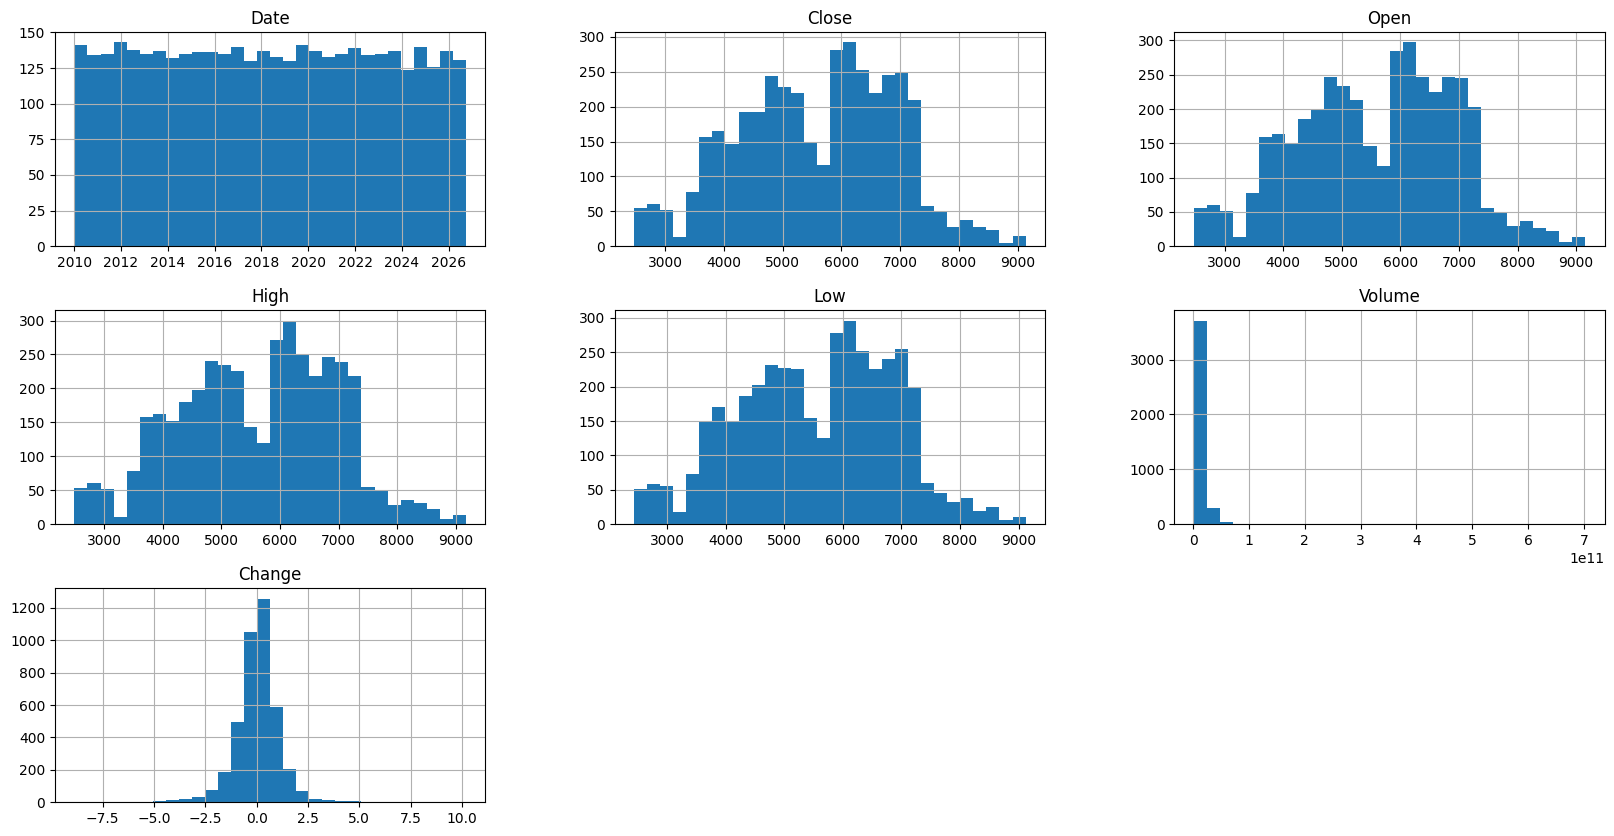

In [139]:
# Plot histogram

ihsg_daily_df.hist(bins=30, figsize=(20,10))
plt.show()

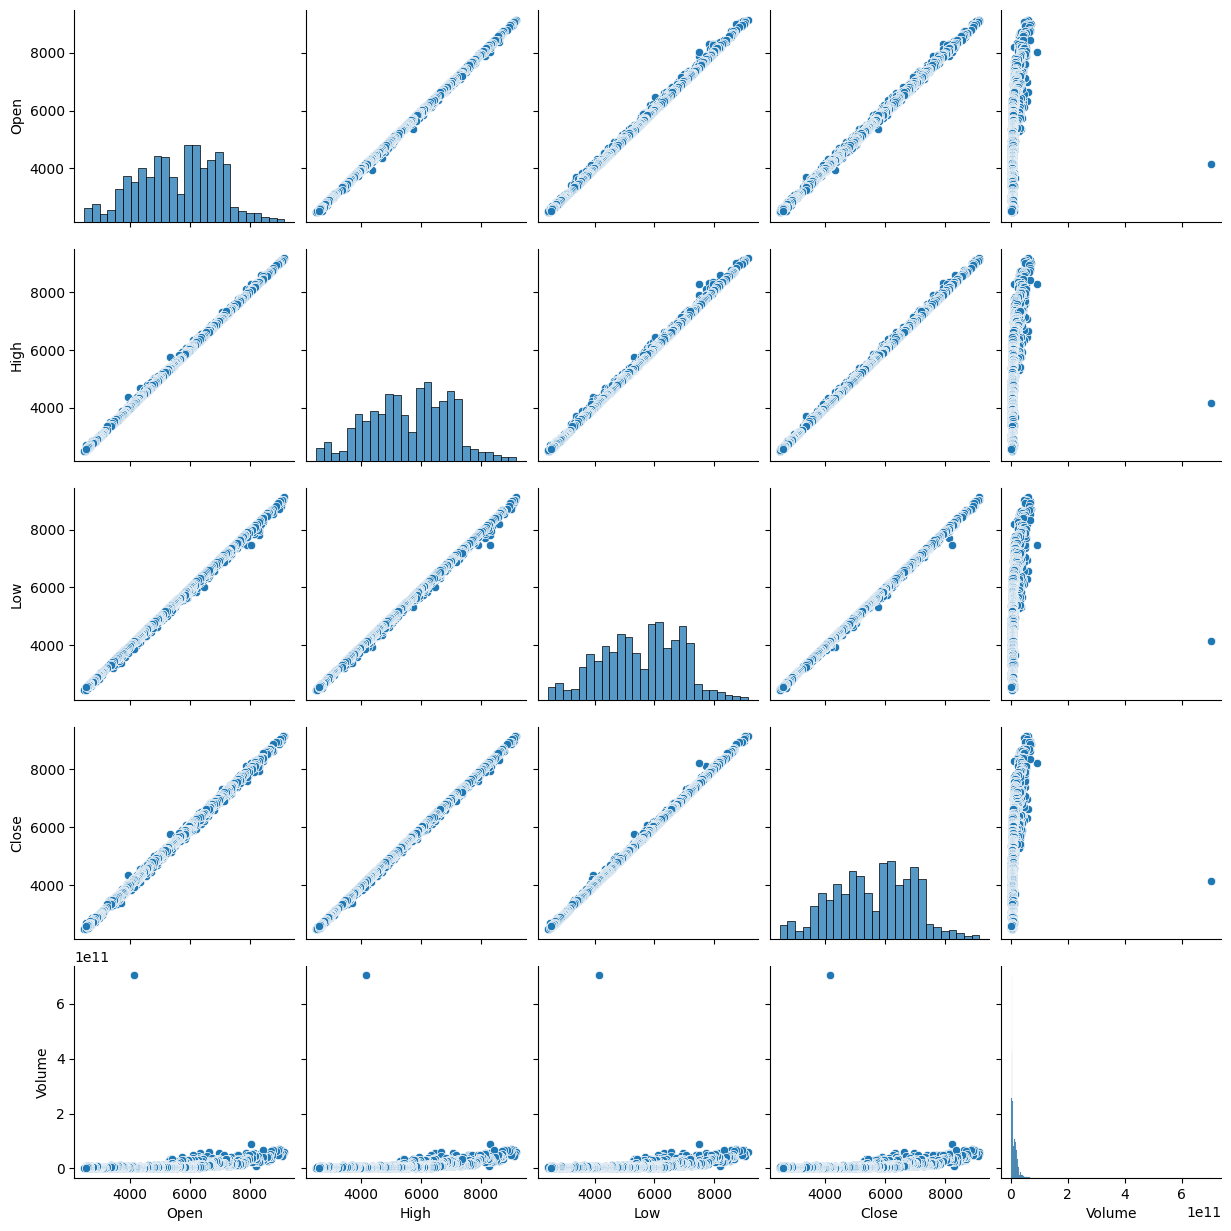

In [140]:
# Plot pairplot

sns.pairplot(
    ihsg_daily_df[
        ['Open', 'High', 'Low', 'Close', 'Volume']
    ]
)

plt.show()

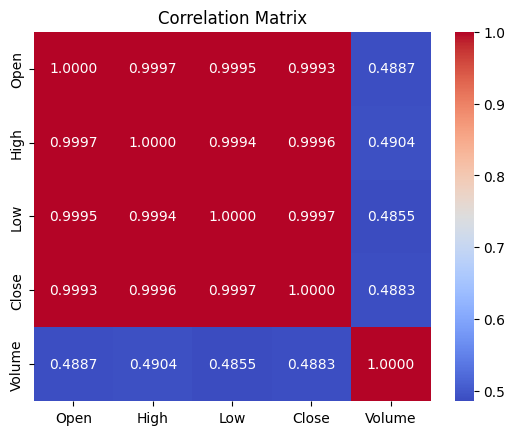

In [142]:
# Correlation matrix

corr_matrix = ihsg_daily_df[
    ['Open', 'High', 'Low', 'Close', 'Volume']
].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.4f'
)

plt.title('Correlation Matrix')
plt.show()

## 4) Preparing data for multiple linear regression

In [143]:
# Define independent variables (X)

x = ihsg_daily_df[
    ['Open', 'High', 'Low', 'Volume']
]

# Define dependent variables (Y)

y = ihsg_daily_df[['Close']]

In [144]:
x

,Open,High,Low,Volume
0,6315.53,6328.41,6231.83,2.385000e+10
1,6364.98,6368.57,6287.46,2.304000e+10
2,6297.96,6380.17,6253.74,2.738000e+10
3,6392.33,6423.84,6258.44,2.926000e+10
4,6446.90,6451.33,6381.57,2.321000e+10
...,...,...,...,...
4068,2586.79,2614.54,2583.85,7.370000e+09
4069,2603.50,2611.60,2570.27,4.550000e+09
4070,2605.48,2622.12,2587.71,5.160000e+09
4071,2575.62,2606.07,2575.62,5.700000e+09


In [146]:
y

,Close
0,6241.89
1,6298.61
2,6374.91
3,6277.04
4,6384.73
...,...
4068,2614.37
4069,2586.89
4070,2603.30
4071,2605.28


In [147]:
# Check shape X and Y

print("X shape:", x.shape)
print("Y shape:", y.shape)

X shape: (4056, 4)
Y shape: (4056, 1)


## 5) Training and Testing Data

In [148]:
# Convert x and y into numpy arrays

x = np.array(x)
y = np.array(y)

In [149]:
# Check the shape

print("X shape:", x.shape)
print("Y shape:", y.shape)

X shape: (4056, 4)
Y shape: (4056, 1)


In [150]:
# Split training and testing data

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size = 0.25,
    random_state = 72
)

In [151]:
# Check training and testing data shape

print("x_train_shape", x_train.shape)
print("x_test_shape", x_test.shape)

print("y_train_shape", y_train.shape)
print("y_test_shape", y_test.shape)

x_train_shape (3042, 4)
x_test_shape (1014, 4)
y_train_shape (3042, 1)
y_test_shape (1014, 1)


# 6) Train Multiple Linear Regression Model

In [152]:
# import linear regression model

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Create multiple regression model
mlr = LinearRegression(fit_intercept=True)

# Train model
mlr.fit(x_train, y_train)

LinearRegression()

In [153]:
# Display coefficient

print("Multiple Linear Regression Coefficient:")
print("Pembukaan:", mlr.coef_[0][0])
print("Tertinggi:", mlr.coef_[0][1])
print("Terendah:", mlr.coef_[0][2])
print("Volume:", mlr.coef_[0][3])

print('\nIntercept:', mlr.intercept_[0])

Multiple Linear Regression Coefficient:
Pembukaan: -0.6022900662731132
Tertinggi: 0.8741739174583524
Terendah: 0.7268843046257243
Volume: 2.7958080295320542e-11

Intercept: 4.254969420685484


## 7) Making Prediction

In [155]:
# Predict close using testing data

y_pred = mlr.predict(x_test)

In [156]:
# Display predicted values

y_pred[:10]

array([[6059.61594258],
       [5187.58816795],
       [8063.51034772],
       [3861.2883045 ],
       [7958.80786158],
       [5225.96330767],
       [3862.08483769],
       [5287.96954517],
       [4186.03475574],
       [2932.55866939]])

## 8) Evaluate Trained Model Performace

In [157]:
# Calculate mean square error

mse = mean_squared_error(
    y_test,
    y_pred
)

print('Mean Squared Error:', mse)

Mean Squared Error: 602.6509558886347


In [158]:
# Calculate root square error

rmse = np.sqrt(mse)

print('Root Mean Squared Error:', rmse)

Root Mean Squared Error: 24.548950199318803


In [159]:
# Calculate mean absolute error

from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(
    y_test,
    y_pred
)

print('Mean Absolute Error:', mae)

Mean Absolute Error: 15.905761564238842


In [160]:
# Calculate R-squared

from sklearn.metrics import r2_score

r2 = r2_score(
    y_test,
    y_pred
)

print('R-squared:', r2)

R-squared: 0.9996630875354026


## 9) Actual vs Predicted Values

In [161]:
# Compare actual vs predicted values

comparison_df = pd.DataFrame({
    'Actual Close': y_test.flatten(),
    'Predicted Close': y_pred.flatten()
})

comparison_df.head(10)

,Actual Close,Predicted Close
0,6011.06,6059.615943
1,5197.25,5187.588168
2,8066.52,8063.510348
3,3889.97,3861.288305
4,7931.25,7958.807862
5,5216.66,5225.963308
6,3880.46,3862.084838
7,5272.98,5287.969545
8,4195.98,4186.034756
9,2914.09,2932.558669


## 10) Visualizing Actual vs Predicted Values

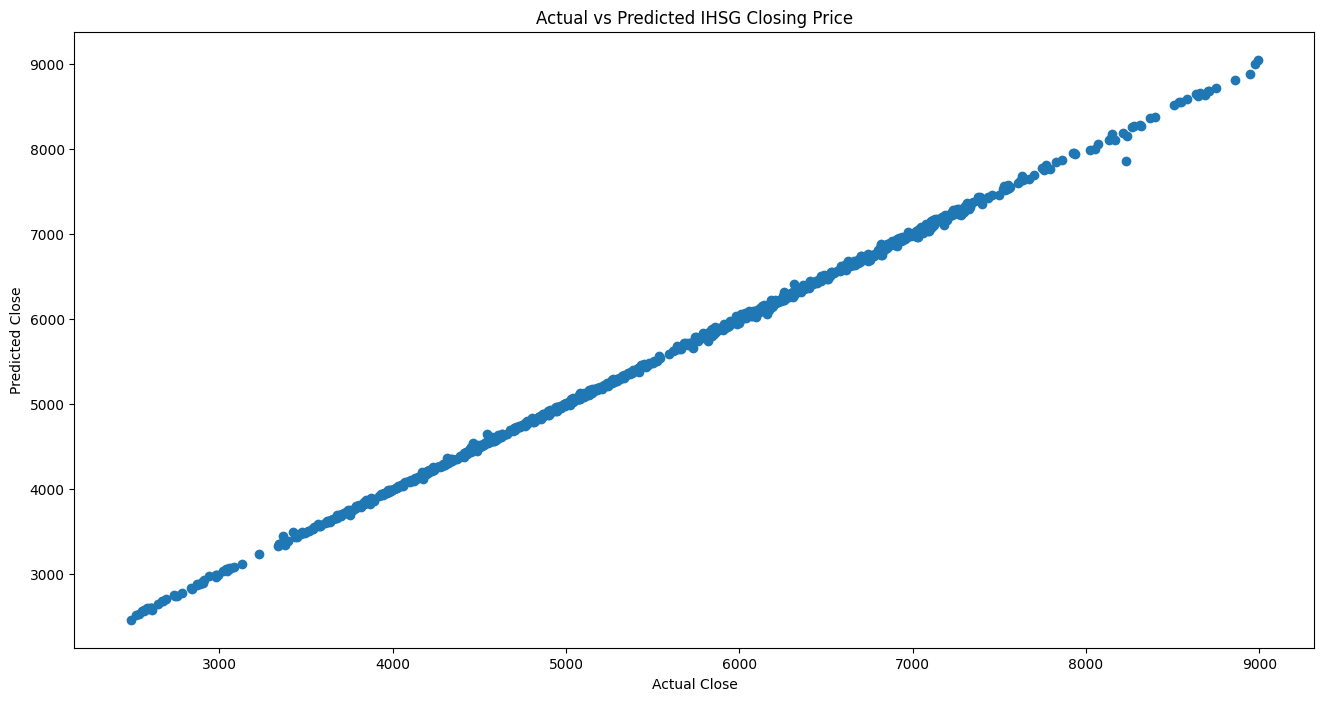

In [162]:
# Plot actual vs predicted values

plt.figure(figsize=(16,8))

plt.scatter(
    y_test,
    y_pred
)

plt.xlabel('Actual Close')
plt.ylabel('Predicted Close')
plt.title('Actual vs Predicted IHSG Closing Price')

plt.show()

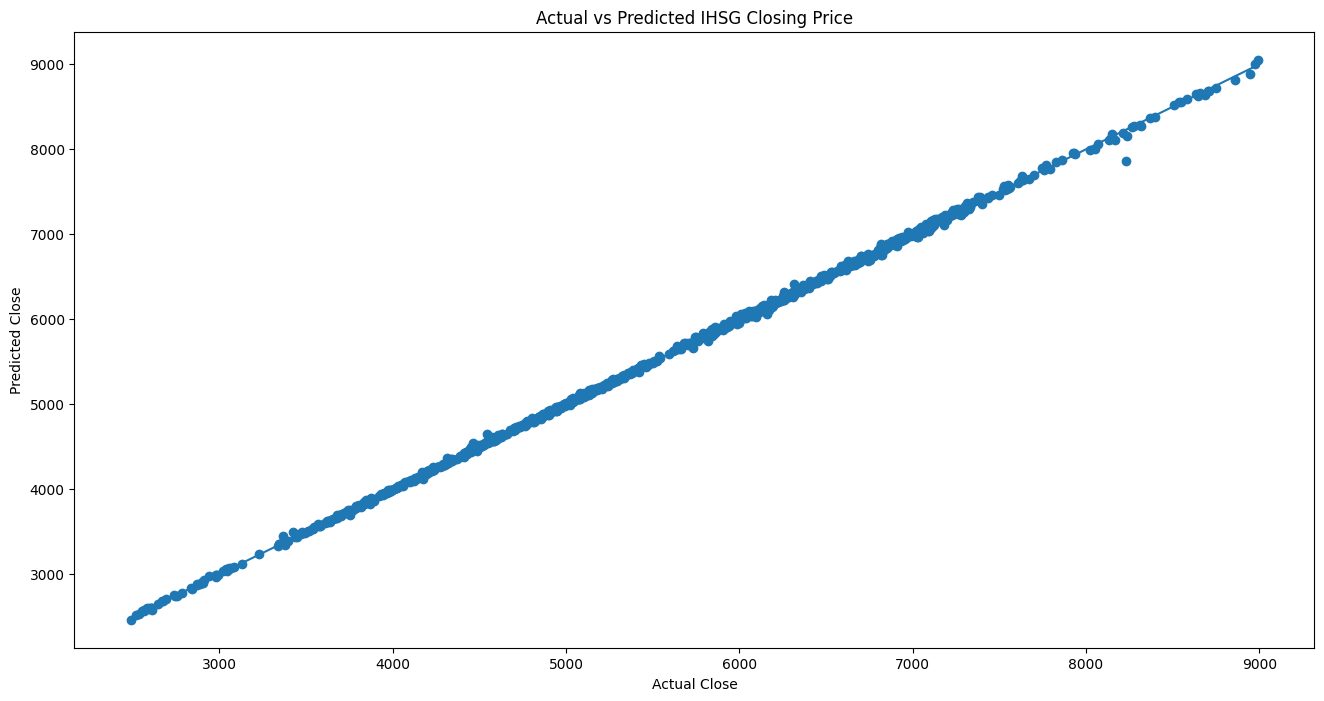

In [163]:
# Plot actual vs predicted values

plt.figure(figsize=(16,8))

plt.scatter(
    y_test,
    y_pred
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()]
)

plt.xlabel('Actual Close')
plt.ylabel('Predicted Close')
plt.title('Actual vs Predicted IHSG Closing Price')

plt.show()

## 11) Checking Regression Coefficient

In [164]:
coefficient_df = pd.DataFrame({
    'Variable': [
        'Open',
        'High',
        'Low',
        'Volume'
    ],
    'Coefficient': mlr.coef_[0]
})

coefficient_df

,Variable,Coefficient
0,Open,-6.022901e-01
1,High,8.741739e-01
2,Low,7.268843e-01
3,Volume,2.795808e-11


In [165]:
# Display the intercept

print('Intercept:', mlr.intercept_[0])

Intercept: 4.254969420685484


## 12) Making New Prediction

In [166]:
# Example input data for prediction
# [Open, High, Low, Volume]

new_value = [[
    7000,
    7100,
    6950,
    1000000000
]]

# Make a prediction

new_prediction = mlr.predict(new_value)

print(
    'Predicted IHSG Close:',
    new_prediction[0][0]
)

Predicted IHSG Close: 7046.733194692274


## 13) Save the Model

In [167]:
import joblib

In [168]:
# Save trained model

model_file = open(
    "multiple_linear_regression_ihsg.pkl",
    "wb"
)

joblib.dump(
    mlr,
    model_file
)

model_file.close()

In [169]:
# Download trained model

files.download(
    'multiple_linear_regression_ihsg.pkl'
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>